In [1]:
#import the library's that will be used
import eurostat
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#retrieve data from eurostat and checking its parameters
class EuroStatExplorer:
    def __init__(self):
        self.toc_df = eurostat.get_toc_df()
        self.raw_data = None

    def search_dataset(self, keyword):
        return eurostat.subset_toc_df(self.toc_df, keyword)

    def get_parameters(self, dataset_code):
        return eurostat.get_pars(dataset_code)

    def load_dataset(self, dataset_code):
        self.raw_data = eurostat.get_data_df(dataset_code)
        return self.raw_data

    def inspect_dataset(self):
        if self.raw_data is None:
            raise ValueError("Load a dataset before inspecting it.")

        print("Shape:", self.raw_data.shape)
        print("Columns:", self.raw_data.columns.tolist())
        print("Data types:")
        print(self.raw_data.dtypes)
        print("First observations:")
        print(self.raw_data.head())

In [3]:
es = EuroStatExplorer()

In [4]:
#checking the parameters and retrieve data from eurostat
print(es.get_parameters("nama_10_a64"))
dataset4 = es.load_dataset("nama_10_a64")
es.inspect_dataset()

['freq', 'unit', 'nace_r2', 'na_item', 'geo']
Shape: (294230, 56)
Columns: ['freq', 'unit', 'nace_r2', 'na_item', 'geo\\TIME_PERIOD', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
Data types:
freq                   str
unit                   str
nace_r2                str
na_item                str
geo\TIME_PERIOD        str
1975               float64
1976               float64
1977               float64
1978               float64
1979               float64
1980               float64
1981               float64
1982               float64
1983               float64
1984               float64
1985               float64
1986          

In [5]:
#naming lists that will  be used to make the graphs
countries = ["PT", "NL", "IT"]
NAMES = {"PT": "Portugal", "NL": "Netherlands", "IT": "Italy"}
COLOR_MAP = {"PT": "#6696b3", "NL": "#d2a071", "IT": "#69a89d"}

In [6]:
#selecting the gross value added of each industry and unit for the three countries, with the years as rows
geo = dataset4.columns[4]
def select_gva(nace, unit):
    rows = dataset4[(dataset4["nace_r2"] == nace) & (dataset4["na_item"] == "B1G") &
                    (dataset4["unit"] == unit) & dataset4[geo].isin(countries)]
    t = rows.set_index(geo).loc[:, "2014":"2024"].T.apply(pd.to_numeric)
    t.index = t.index.astype(int)
    t.index.name = "year"
    t.columns.name = "country"
    return t[countries]
#H50 is water transport, H52 is warehousing and support (port services),
#H is all transport and TOTAL is the whole economy
h50_cp = select_gva("H50", "CP_MEUR")
h52_cp = select_gva("H52", "CP_MEUR")
h_cp = select_gva("H", "CP_MEUR")
total_cp = select_gva("TOTAL", "CP_MEUR")
h50_real = select_gva("H50", "CLV20_MEUR")
h52_real = select_gva("H52", "CLV20_MEUR")
total_real = select_gva("TOTAL", "CLV20_MEUR")
h50_pyp = select_gva("H50", "PYP_MEUR")
h52_pyp = select_gva("H52", "PYP_MEUR")

print("H50, current prices (€ million)")
print(h50_cp, "\n")
print("H52, current prices (€ million)")
print(h52_cp)

H50, current prices (€ million)
country     PT      NL      IT
year                          
2014     132.7  2752.0  3489.8
2015     132.5  3100.0  3969.8
2016     129.2  2791.0  3779.5
2017     131.0  2825.0  3894.0
2018     120.1  2768.0  3743.9
2019     155.7  2864.0  3954.0
2020     125.3  2901.0  1637.8
2021     173.6  3413.0  2200.9
2022     240.5  4928.0  3222.9
2023     235.1  5084.0  5085.6
2024     253.1  4931.0  5025.9 

H52, current prices (€ million)
country      PT       NL       IT
year                             
2014     2805.3  10600.0  30303.3
2015     3008.8  11237.0  29783.1
2016     3158.4  11086.0  30687.5
2017     3472.1  11787.0  31931.2
2018     3602.5  12249.0  33247.4
2019     3860.5  12932.0  33472.0
2020     2877.7  12478.0  29215.1
2021     3232.0  13950.0  34271.2
2022     4072.0  17429.0  39401.2
2023     4547.7  17733.0  40912.7
2024     4960.1  18484.0  44120.3


In [7]:
#getting the goods handled in ports to compare with the gross value added
cwh = es.load_dataset("mar_mg_aa_cwh")
port_geo = cwh.columns[2]
tonnes = cwh[(cwh["unit"] == "THS_T") & cwh[port_geo].isin(countries)].set_index(port_geo).loc[:, "2014":"2024"].T
tonnes.index = tonnes.index.astype(int)
tonnes.index.name = "year"
tonnes.columns.name = "country"
tonnes = tonnes[countries]
print("Goods handled (thousand tonnes)")
print(tonnes)

Goods handled (thousand tonnes)
country       PT        NL        IT
year                                
2014     80156.0  571636.0  443141.0
2015     86769.0  588506.0  458020.0
2016     91344.0  581070.0  461990.0
2017     93356.0  593489.0  475164.0
2018     90361.0  599843.0  501958.0
2019     85320.0  602821.0  508074.0
2020     79371.0  547758.0  469635.0
2021     83080.0  580179.0  501603.0
2022     85025.0  589935.0  509397.0
2023     82110.0  545105.0  488888.0
2024     85669.0  538120.0  488556.0


In [8]:
#preparing the indicators such as shares of GVA, H50 + H52 together and GVA per tonne
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

port_cp = h50_cp + h52_cp
port_real = ((h50_pyp + h52_pyp) / port_cp.shift(1)).fillna(1).cumprod() * port_cp.loc[2014]
#real H50 + H52 made with previous year prices, because chain-linked volumes can't be added
h50_share = h50_cp / total_cp * 100
h52_share = h52_cp / total_cp * 100
port_share = port_cp / total_cp * 100
eur_per_tonne = port_cp * 1e6 / (tonnes * 1000)
#checking that there are no missing values
missing = pd.concat([h50_cp, h52_cp, h_cp, total_cp, h50_real, h52_real, total_real,
                     h50_pyp.loc[2015:], h52_pyp.loc[2015:], tonnes]).isna().sum().sum()
print("Missing values:", int(missing))

Missing values: 0


In [9]:
#making the table of Water transport (H50) and port services (H52) with the averages 2014–2024 and the real growth
table2 = pd.DataFrame({
    "Water transport (H50), % of total GVA": h50_share.mean(),
    "Warehousing and support (H52), % of total GVA": h52_share.mean(),
    "H50 + H52, % of total GVA": port_share.mean(),
    "H50 + H52, % of transportation and storage (H)": (port_cp / h_cp * 100).mean(),
    "H50, % of H50 + H52": (h50_cp / port_cp * 100).mean(),
    "GVA of H50 + H52 per tonne handled (€)": eur_per_tonne.mean(),
    "H50 + H52, real growth 2014–2024 (%)": (port_real.loc[2024] / port_real.loc[2014] - 1) * 100,
    "Total GVA, real growth 2014–2024 (%)": (total_real.loc[2024] / total_real.loc[2014] - 1) * 100,
}).rename(index=NAMES).round(2)
print("Average 2014–2024")
print(table2.T)

Average 2014–2024
country                                         Portugal  Netherlands  Italy
Water transport (H50), % of total GVA               0.09         0.45   0.22
Warehousing and support (H52), % of total GVA       1.92         1.79   2.09
H50 + H52, % of total GVA                           2.00         2.24   2.31
H50 + H52, % of transportation and storage (H)     42.25        47.77  46.61
H50, % of H50 + H52                                 4.37        20.20   9.53
GVA of H50 + H52 per tonne handled (€)             44.03        29.88  78.55
H50 + H52, real growth 2014–2024 (%)               41.40        22.39   9.17
Total GVA, real growth 2014–2024 (%)               23.53        22.00  13.42


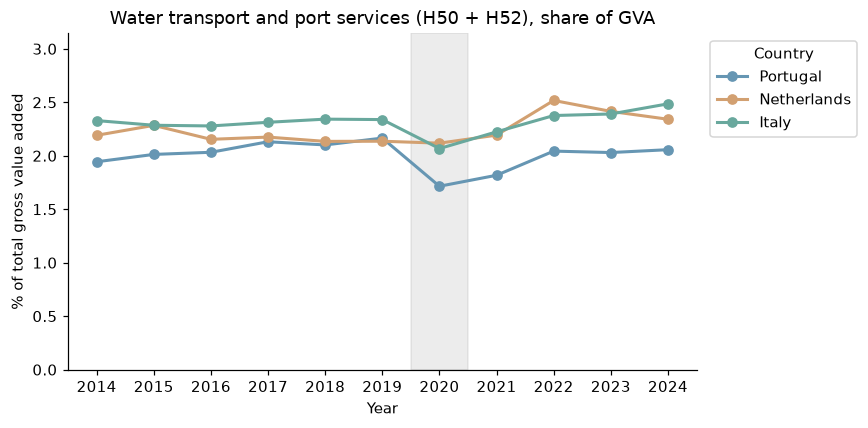

country  Portugal  Netherlands  Italy
year                                 
2014         1.94         2.19   2.33
2015         2.01         2.28   2.29
2016         2.03         2.15   2.28
2017         2.13         2.17   2.31
2018         2.10         2.13   2.34
2019         2.17         2.14   2.34
2020         1.71         2.12   2.07
2021         1.82         2.19   2.22
2022         2.04         2.52   2.38
2023         2.03         2.42   2.39
2024         2.06         2.34   2.49


In [10]:
#making a multiple line chart with the share of H50 + H52 in the GVA over time
fig, ax = plt.subplots(figsize=(8, 4))
for c in countries:
    ax.plot(port_share.index, port_share[c], marker="o", linewidth=2, color=COLOR_MAP[c], label=NAMES[c])
ax.axvspan(2019.5, 2020.5, color="grey", alpha=0.15)
ax.set(title="Water transport and port services (H50 + H52), share of GVA", xlabel="Year",
       ylabel="% of total gross value added", ylim=(0, port_share.max().max() * 1.25))
ax.set_xticks(port_share.index)
ax.legend(title="Country", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()
print(port_share.rename(columns=NAMES).round(2))

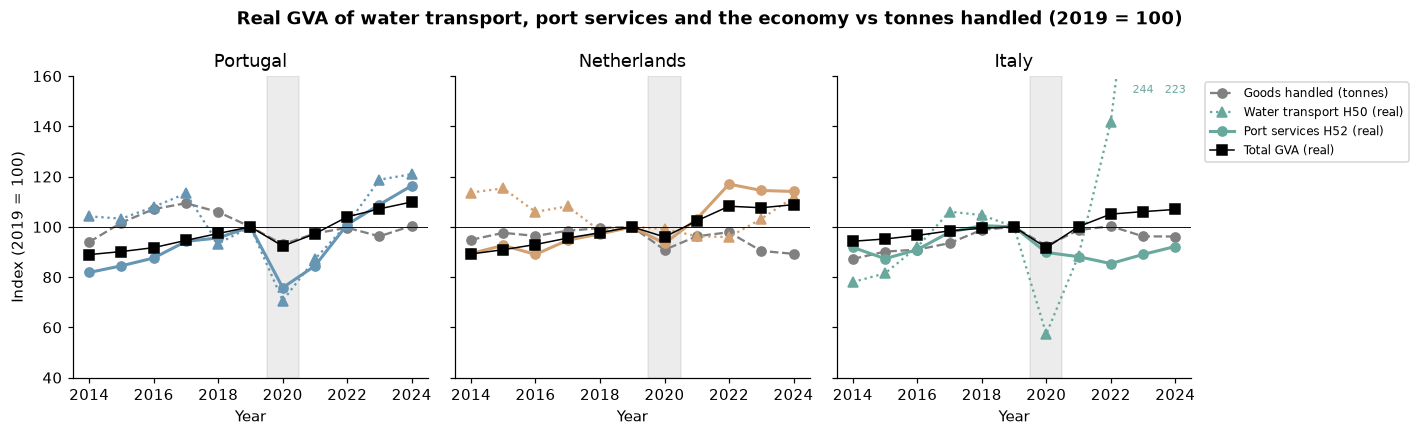

Change 2020 vs 2019 (%)
             tonnes  H50 real  H52 real  total GVA real
country                                                
Portugal       -7.0     -29.4     -24.2            -7.7
Netherlands    -9.1      -0.9      -6.6            -4.0
Italy          -7.6     -42.7     -10.2            -8.3

H50 + H52 (real) back to the 2019 level in: {'Portugal': 2022, 'Netherlands': 2021, 'Italy': 'not by 2024'}

Index 2019 = 100
        H50 real                    H52 real                   
country Portugal Netherlands  Italy Portugal Netherlands  Italy
year                                                           
2014       104.2       113.7   78.0     81.9        89.4   91.8
2015       103.3       115.3   81.5     84.5        92.6   87.3
2016       107.9       106.0   92.0     87.6        89.0   90.9
2017       113.3       108.2  106.0     94.2        94.7   97.9
2018        93.3        98.3  104.7     95.6        97.2  100.5
2019       100.0       100.0  100.0    100.0       100.0 

In [11]:
#making a graph comparing the real GVA with the tonnes handled, index 2019 = 100
def idx(t):
    return t / t.loc[2019] * 100

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, c in zip(axes, countries):
    ax.plot(tonnes.index, idx(tonnes)[c], color="grey", linestyle="--", marker="o", label="Goods handled (tonnes)")
    ax.plot(h50_real.index, idx(h50_real)[c], color=COLOR_MAP[c], linestyle=":", marker="^", label="Water transport H50 (real)")
    ax.plot(h52_real.index, idx(h52_real)[c], color=COLOR_MAP[c], linewidth=2, marker="o", label="Port services H52 (real)")
    ax.plot(total_real.index, idx(total_real)[c], color="black", linewidth=1, marker="s", label="Total GVA (real)")
    for year, value in idx(h50_real)[c][idx(h50_real)[c] > 160].items():
        ax.annotate(f"{value:.0f}", xy=(year, 160), xytext=(0, -11), textcoords="offset points",
                    ha="center", fontsize=7, color=COLOR_MAP[c])
    ax.axhline(100, color="black", linewidth=0.6)
    ax.axvspan(2019.5, 2020.5, color="grey", alpha=0.15)
    ax.set(title=NAMES[c], xlabel="Year", ylim=(40, 160))
    ax.set_xticks([2014, 2016, 2018, 2020, 2022, 2024])
axes[0].set_ylabel("Index (2019 = 100)")
axes[2].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Real GVA of water transport, port services and the economy vs tonnes handled (2019 = 100)",
             fontweight="bold")
plt.tight_layout()
plt.show()
#changes in 2020 compared with 2019
covid = pd.DataFrame({
    "tonnes": (tonnes.loc[2020] / tonnes.loc[2019] - 1) * 100,
    "H50 real": (h50_real.loc[2020] / h50_real.loc[2019] - 1) * 100,
    "H52 real": (h52_real.loc[2020] / h52_real.loc[2019] - 1) * 100,
    "total GVA real": (total_real.loc[2020] / total_real.loc[2019] - 1) * 100,
}).rename(index=NAMES).round(1)
print("Change 2020 vs 2019 (%)")
print(covid)
#checking in which year H50 + H52 got back to the 2019 level
recovery = {NAMES[c]: next((y for y in port_real.index if y > 2020 and port_real.loc[y, c] >= port_real.loc[2019, c]),
                           "not by 2024") for c in countries}
print("\nH50 + H52 (real) back to the 2019 level in:", recovery)
print("\nIndex 2019 = 100")
print(pd.concat({"H50 real": idx(h50_real), "H52 real": idx(h52_real)}, axis=1).rename(columns=NAMES, level=1).round(1))

In [12]:
#real growth on the previous year of H50 and H52, used in the text under figure 4
growth_ind = pd.concat({"H50": h50_real.pct_change(fill_method=None) * 100,
                        "H52": h52_real.pct_change(fill_method=None) * 100}, axis=1).loc[2015:]
growth_ind = growth_ind.rename(columns=NAMES, level=1).round(1)
print("Real GVA growth on previous year (%)")
print(growth_ind)
print(growth_ind.agg(["min", "max"]))
print("\nH52 real, change 2014–2024 (%):",
      ((h52_real.loc[2024] / h52_real.loc[2014] - 1) * 100).round(1).rename(NAMES).to_dict())

Real GVA growth on previous year (%)
             H50                        H52                  
country Portugal Netherlands Italy Portugal Netherlands Italy
year                                                         
2015        -0.9         1.5   4.4      3.2         3.6  -4.9
2016         4.5        -8.1  12.9      3.7        -3.9   4.1
2017         5.0         2.1  15.3      7.6         6.4   7.6
2018       -17.6        -9.1  -1.3      1.5         2.6   2.7
2019         7.1         1.7  -4.5      4.6         2.9  -0.5
2020       -29.4        -0.9 -42.7    -24.2        -6.6 -10.2
2021        23.5        -2.9  54.4     11.5        10.4  -1.9
2022        15.8        -0.4  60.2     19.4        13.5  -3.1
2023        17.6         7.5  72.0      7.9        -2.2   4.3
2024         1.9         8.3  -8.6      6.9        -0.3   3.5
             H50                        H52                  
country Portugal Netherlands Italy Portugal Netherlands Italy
min        -29.4        -9.1 -42.

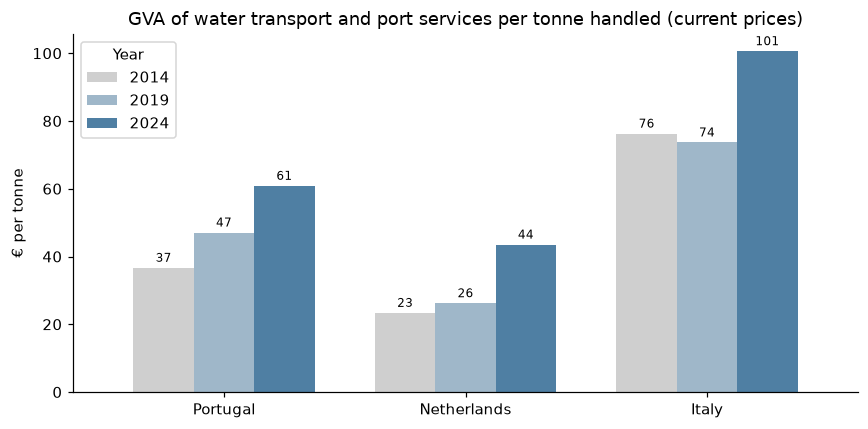

country  Portugal  Netherlands  Italy
year                                 
2014         37.0         23.0   76.0
2015         36.0         24.0   74.0
2016         36.0         24.0   75.0
2017         39.0         25.0   75.0
2018         41.0         25.0   74.0
2019         47.0         26.0   74.0
2020         38.0         28.0   66.0
2021         41.0         30.0   73.0
2022         51.0         38.0   84.0
2023         58.0         42.0   94.0
2024         61.0         44.0  101.0

Change 2019–2024 (%): {'Portugal': 29.0, 'Netherlands': 66.0, 'Italy': 37.0}
Italy / Netherlands: {2014: 3.3, 2024: 2.3}


In [13]:
#making a bar graph  with GVA of water transport and port services per tonne handled in 2014, 2019 and 2024
PICK = [2014, 2019, 2024]
ax = eur_per_tonne.loc[PICK].T.rename(index=NAMES).plot(
    kind="bar", figsize=(8, 4), rot=0, width=0.75, color=["#cfcfcf", "#9fb7c9", "#4f7fa3"],
    title="GVA of water transport and port services per tonne handled (current prices)")
for cont in ax.containers:
    ax.bar_label(cont, labels=[f"{v:.0f}" for v in cont.datavalues], fontsize=8, padding=2)
ax.set(xlabel="", ylabel="€ per tonne")
ax.legend(title="Year")
plt.tight_layout()
plt.show()
print(eur_per_tonne.rename(columns=NAMES).round(0))
print("\nChange 2019–2024 (%):",
      ((eur_per_tonne.loc[2024] / eur_per_tonne.loc[2019] - 1) * 100).round(0).rename(NAMES).to_dict())
print("Italy / Netherlands:", (eur_per_tonne["IT"] / eur_per_tonne["NL"]).loc[[2014, 2024]].round(1).to_dict())